In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("../data/cleaned/Hotel_Reviews_Sentiment.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (515212, 21)


In [3]:
print("===== DATASET VERIFICATION =====")

print("\nShape:")
print(df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isna().sum().sum())

print("\nData types:")
print(df.dtypes)

===== DATASET VERIFICATION =====

Shape:
(515212, 21)

Columns:
['Hotel_Address', 'Additional_Number_of_Scoring', 'Review_Date', 'Average_Score', 'Hotel_Name', 'Reviewer_Nationality', 'Negative_Review', 'Review_Total_Negative_Word_Counts', 'Total_Number_of_Reviews', 'Positive_Review', 'Review_Total_Positive_Word_Counts', 'Total_Number_of_Reviews_Reviewer_Has_Given', 'Reviewer_Score', 'Tags', 'days_since_review', 'lat', 'lng', 'Rating_Sentiment', 'Review_Text', 'VADER_Compound', 'VADER_Sentiment']

Missing values:
7897

Data types:
Hotel_Address                                     str
Additional_Number_of_Scoring                    int64
Review_Date                                       str
Average_Score                                 float64
Hotel_Name                                        str
Reviewer_Nationality                              str
Negative_Review                                   str
Review_Total_Negative_Word_Counts               int64
Total_Number_of_Reviews        

In [4]:
missing_values = df.isna().sum()

missing_values = missing_values[missing_values > 0].sort_values(
    ascending=False
)

print("===== MISSING VALUES BY COLUMN =====")
print(missing_values)

===== MISSING VALUES BY COLUMN =====
lng                3268
lat                3268
Negative_Review    1319
Positive_Review      42
dtype: int64


In [5]:
df["Review_Date"] = pd.to_datetime(
    df["Review_Date"],
    errors="coerce"
)

print("Review_Date dtype:", df["Review_Date"].dtype)
print("Missing Review_Date:", df["Review_Date"].isna().sum())

Review_Date dtype: datetime64[us]
Missing Review_Date: 0


In [6]:
print("===== REVIEW DATE RANGE =====")

print("Earliest Review Date:", df["Review_Date"].min())
print("Latest Review Date:", df["Review_Date"].max())
print("Total Days:", (df["Review_Date"].max() - df["Review_Date"].min()).days)

===== REVIEW DATE RANGE =====
Earliest Review Date: 2015-08-04 00:00:00
Latest Review Date: 2017-08-03 00:00:00
Total Days: 730


In [7]:
daily_reviews = (
    df.groupby("Review_Date")
    .size()
    .reset_index(name="Review_Count")
)

print(daily_reviews.head())
print("\nTotal unique review dates:", len(daily_reviews))

  Review_Date  Review_Count
0  2015-08-04          1346
1  2015-08-05           421
2  2015-08-06           797
3  2015-08-07           344
4  2015-08-08           573

Total unique review dates: 731


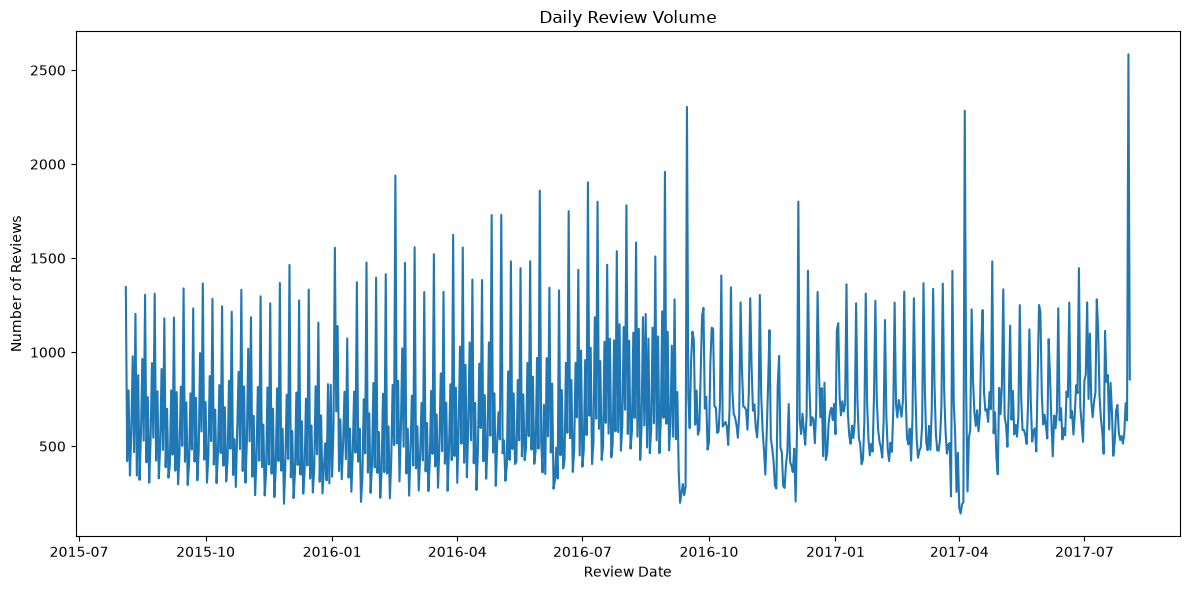

In [8]:
plt.figure(figsize=(12, 6))

plt.plot(
    daily_reviews["Review_Date"],
    daily_reviews["Review_Count"]
)

plt.title("Daily Review Volume")
plt.xlabel("Review Date")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

In [9]:
df["Review_Month"] = df["Review_Date"].dt.to_period("M").astype(str)

monthly_reviews = (
    df.groupby("Review_Month")
    .size()
    .reset_index(name="Review_Count")
)

print(monthly_reviews.head())
print("\nTotal months:", len(monthly_reviews))

  Review_Month  Review_Count
0      2015-08         19287
1      2015-09         19689
2      2015-10         19449
3      2015-11         18039
4      2015-12         17914

Total months: 25


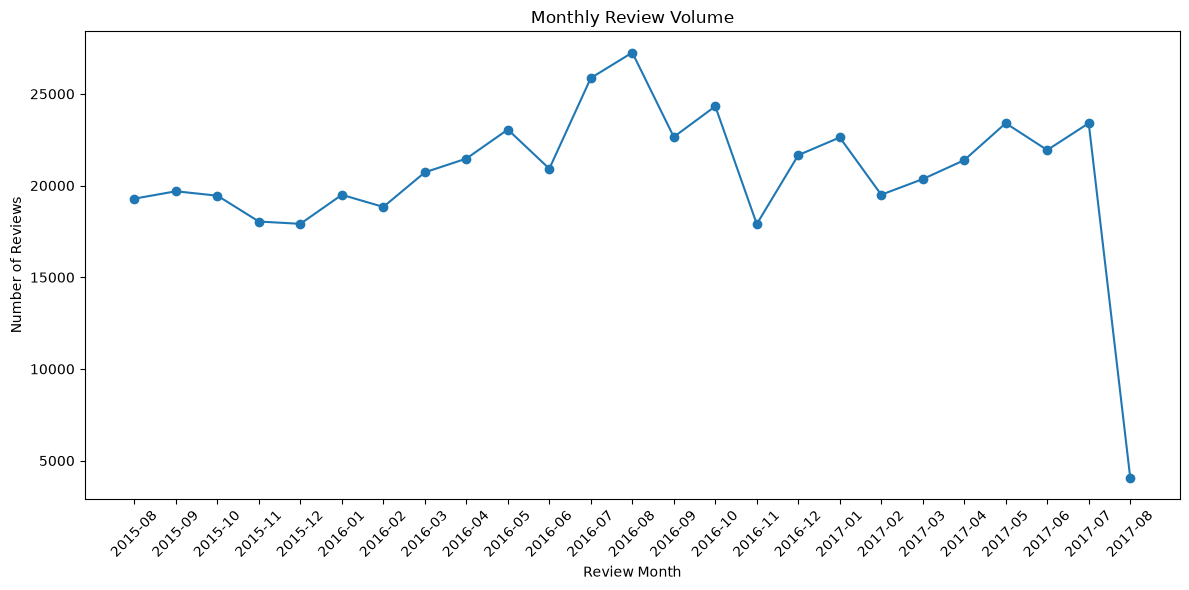

In [10]:
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_reviews["Review_Month"],
    monthly_reviews["Review_Count"],
    marker="o"
)

plt.title("Monthly Review Volume")
plt.xlabel("Review Month")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [11]:
highest_review_months = (
    monthly_reviews
    .sort_values("Review_Count", ascending=False)
    .head(5)
)

lowest_review_months = (
    monthly_reviews
    .sort_values("Review_Count", ascending=True)
    .head(5)
)

print("===== TOP 5 HIGHEST REVIEW-VOLUME MONTHS =====")
print(highest_review_months)

print("\n===== TOP 5 LOWEST REVIEW-VOLUME MONTHS =====")
print(lowest_review_months)

===== TOP 5 HIGHEST REVIEW-VOLUME MONTHS =====
   Review_Month  Review_Count
12      2016-08         27252
11      2016-07         25865
14      2016-10         24324
23      2017-07         23402
21      2017-05         23402

===== TOP 5 LOWEST REVIEW-VOLUME MONTHS =====
   Review_Month  Review_Count
24      2017-08          4076
15      2016-11         17900
4       2015-12         17914
3       2015-11         18039
6       2016-02         18836


In [12]:
df["Review_Year"] = df["Review_Date"].dt.year

yearly_reviews = (
    df.groupby("Review_Year")
    .size()
    .reset_index(name="Review_Count")
)

print("===== YEARLY REVIEW VOLUME =====")
print(yearly_reviews)

===== YEARLY REVIEW VOLUME =====
   Review_Year  Review_Count
0         2015         94378
1         2016        264153
2         2017        156681


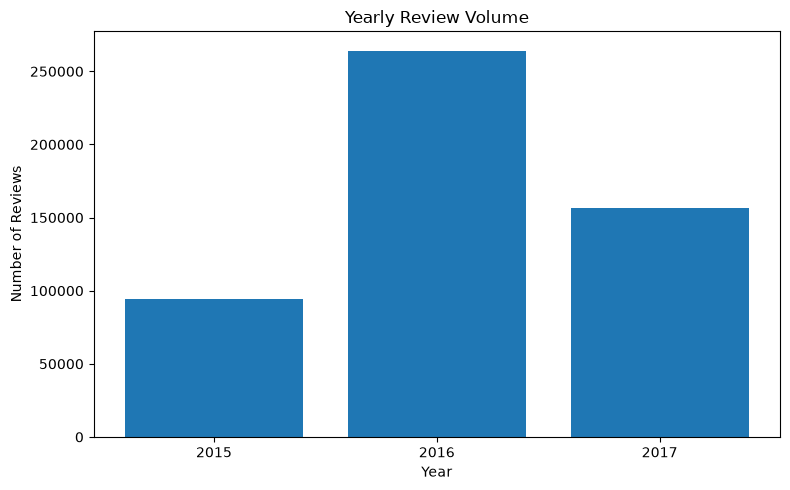

In [13]:
plt.figure(figsize=(8, 5))

plt.bar(
    yearly_reviews["Review_Year"].astype(str),
    yearly_reviews["Review_Count"]
)

plt.title("Yearly Review Volume")
plt.xlabel("Year")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

In [14]:
def extract_city(address):
    address = str(address)

    if "Amsterdam" in address:
        return "Amsterdam"
    elif "Barcelona" in address:
        return "Barcelona"
    elif "London" in address:
        return "London"
    elif "Milan" in address:
        return "Milan"
    elif "Paris" in address:
        return "Paris"
    elif "Vienna" in address:
        return "Vienna"
    else:
        return "Unknown"


df["City"] = df["Hotel_Address"].apply(extract_city)

city_reviews = (
    df["City"]
    .value_counts()
    .reset_index()
)

city_reviews.columns = ["City", "Review_Count"]

print("===== REVIEW VOLUME BY CITY =====")
print(city_reviews)

===== REVIEW VOLUME BY CITY =====
        City  Review_Count
0     London        262298
1  Barcelona         60149
2      Paris         59191
3  Amsterdam         57433
4     Vienna         38937
5      Milan         37204


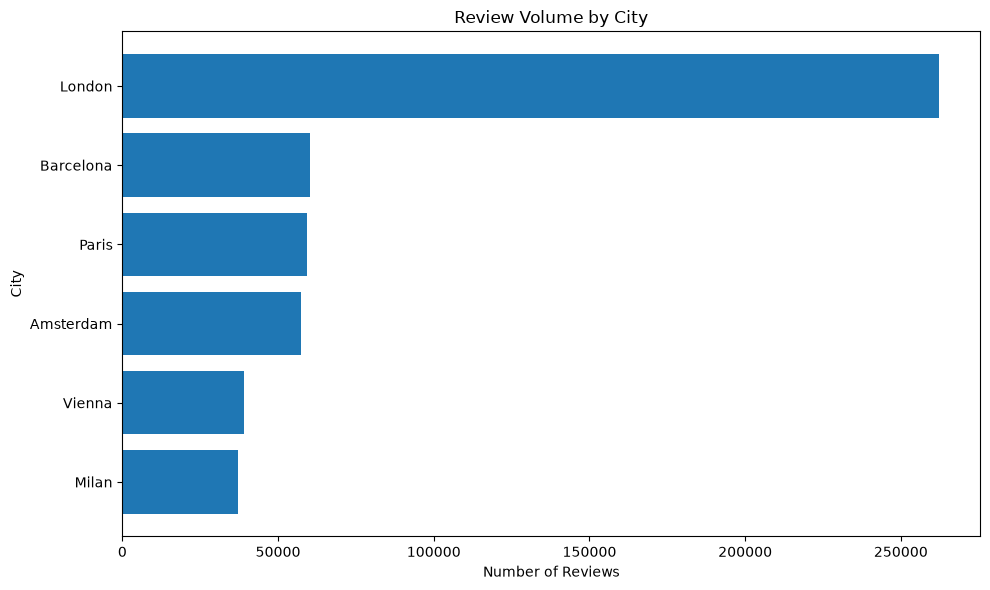

In [16]:
plt.figure(figsize=(10, 6))

plt.barh(
    city_reviews["City"][::-1],
    city_reviews["Review_Count"][::-1]
)

plt.title("Review Volume by City")
plt.xlabel("Number of Reviews")
plt.ylabel("City")
plt.tight_layout()
plt.show()

In [17]:
city_monthly_reviews = (
    df.groupby(["Review_Month", "City"])
    .size()
    .reset_index(name="Review_Count")
)

city_monthly_pivot = (
    city_monthly_reviews
    .pivot(
        index="Review_Month",
        columns="City",
        values="Review_Count"
    )
    .fillna(0)
)

print(city_monthly_pivot.head())

City          Amsterdam  Barcelona  London  Milan  Paris  Vienna
Review_Month                                                    
2015-08            1874       2581    8516   1547   2951    1818
2015-09            1773       2675    9092   1555   2926    1668
2015-10            1875       2379    9463   1424   2768    1540
2015-11            1905       1994    9605   1187   2098    1250
2015-12            1758       1578   10166    966   1625    1821


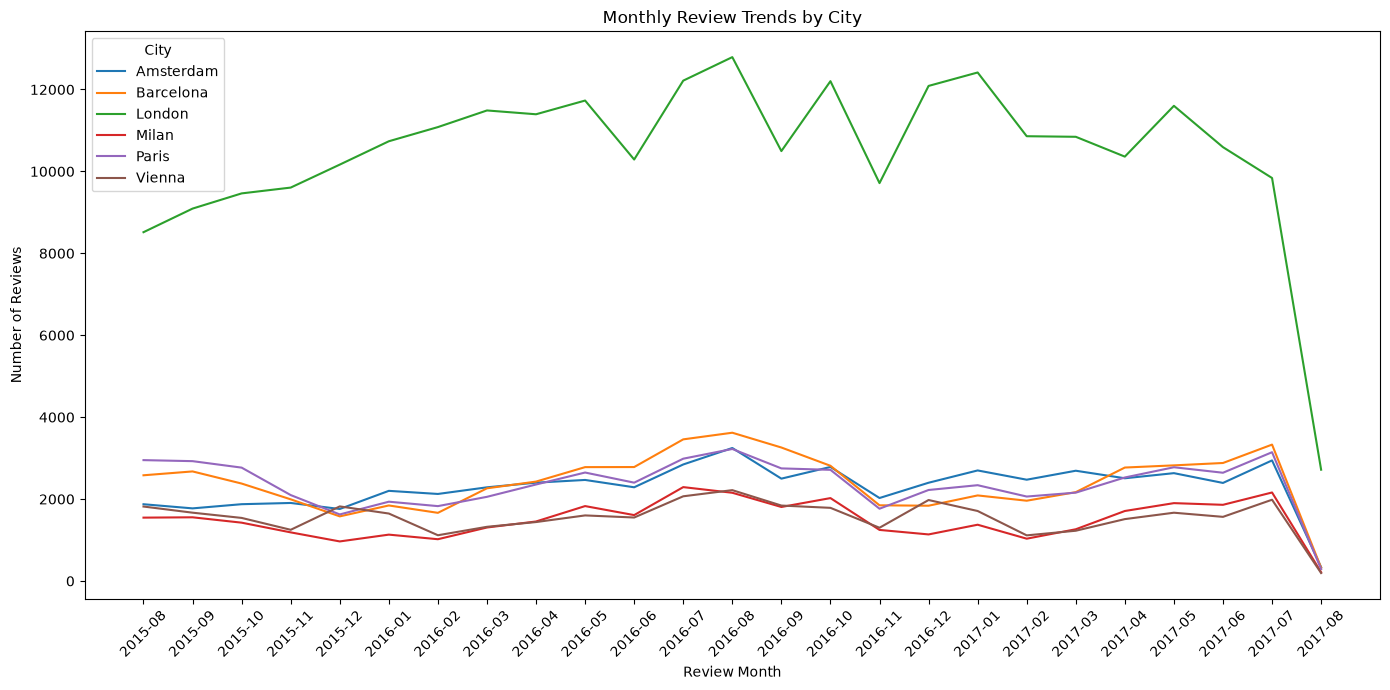

In [18]:
plt.figure(figsize=(14, 7))

for city in city_monthly_pivot.columns:
    plt.plot(
        city_monthly_pivot.index,
        city_monthly_pivot[city],
        label=city
    )

plt.title("Monthly Review Trends by City")
plt.xlabel("Review Month")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=45)
plt.legend(title="City")
plt.tight_layout()
plt.show()

In [19]:
hotel_reviews = (
    df["Hotel_Name"]
    .value_counts()
    .reset_index()
)

hotel_reviews.columns = ["Hotel_Name", "Review_Count"]

print("===== TOP 10 MOST REVIEWED HOTELS =====")
print(hotel_reviews.head(10))

===== TOP 10 MOST REVIEWED HOTELS =====
                                          Hotel_Name  Review_Count
0         Britannia International Hotel Canary Wharf          4789
1                                Strand Palace Hotel          4256
2               Park Plaza Westminster Bridge London          4169
3             Copthorne Tara Hotel London Kensington          3577
4  DoubleTree by Hilton Hotel London Tower of London          3212
5                      Grand Royale London Hyde Park          2958
6                      Holiday Inn London Kensington          2768
7                            Hilton London Metropole          2628
8                 Millennium Gloucester Hotel London          2565
9                     Intercontinental London The O2          2551


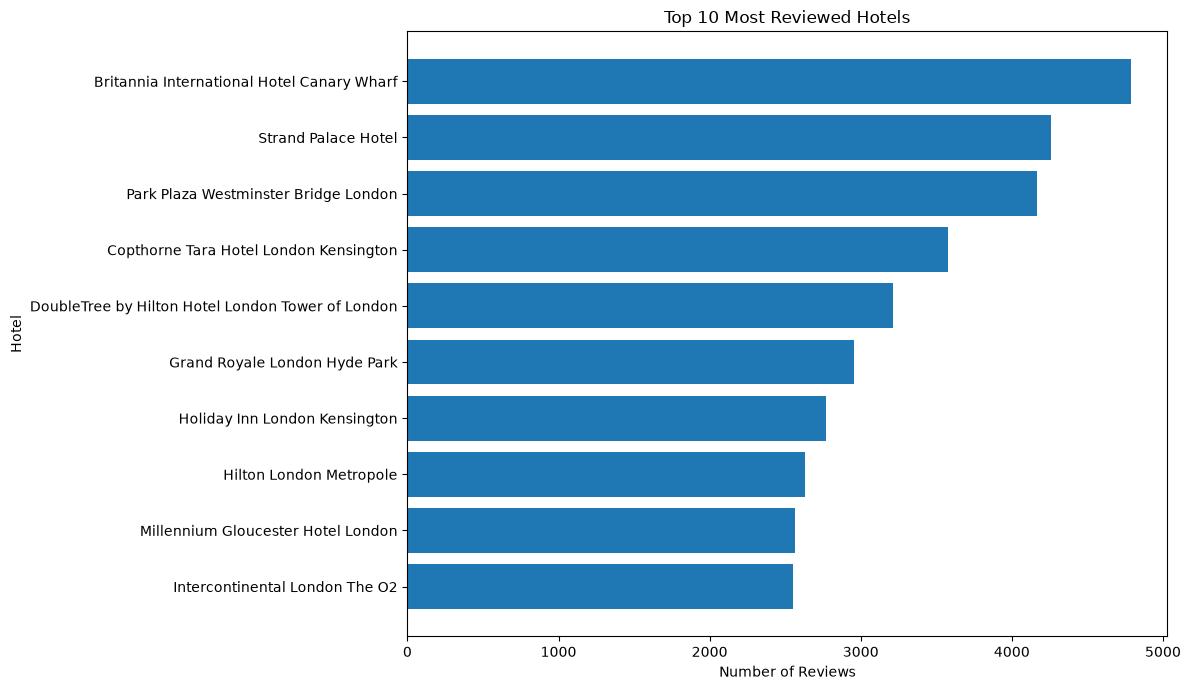

In [20]:
top_10_hotels = hotel_reviews.head(10)

plt.figure(figsize=(12, 7))

plt.barh(
    top_10_hotels["Hotel_Name"][::-1],
    top_10_hotels["Review_Count"][::-1]
)

plt.title("Top 10 Most Reviewed Hotels")
plt.xlabel("Number of Reviews")
plt.ylabel("Hotel")
plt.tight_layout()
plt.show()

In [21]:
import re

def extract_nights(tags):
    match = re.search(r"Stayed (\d+) night", str(tags))
    if match:
        return int(match.group(1))
    return np.nan

df["Stay_Nights"] = df["Tags"].apply(extract_nights)

print("===== STAY DURATION ANALYSIS =====")
print("Missing stay duration:", df["Stay_Nights"].isna().sum())
print("Average stay:", df["Stay_Nights"].mean())
print("Median stay:", df["Stay_Nights"].median())
print("Minimum stay:", df["Stay_Nights"].min())
print("Maximum stay:", df["Stay_Nights"].max())

===== STAY DURATION ANALYSIS =====
Missing stay duration: 192
Average stay: 2.361890800357268
Median stay: 2.0
Minimum stay: 1.0
Maximum stay: 31.0


In [22]:
stay_duration = (
    df["Stay_Nights"]
    .value_counts()
    .sort_index()
    .reset_index()
)

stay_duration.columns = ["Stay_Nights", "Review_Count"]

print("===== STAY DURATION DISTRIBUTION =====")
print(stay_duration)

===== STAY DURATION DISTRIBUTION =====
    Stay_Nights  Review_Count
0           1.0        193497
1           2.0        133809
2           3.0         95706
3           4.0         47750
4           5.0         20818
5           6.0          9754
6           7.0          7387
7           8.0          2498
8           9.0          1293
9          10.0           887
10         11.0           417
11         12.0           316
12         13.0           246
13         14.0           247
14         15.0           117
15         16.0            57
16         17.0            42
17         18.0            33
18         19.0            29
19         20.0            19
20         21.0            23
21         22.0            10
22         23.0            10
23         24.0             6
24         25.0             7
25         26.0             7
26         27.0            11
27         28.0             7
28         29.0             5
29         30.0            11
30         31.0             1


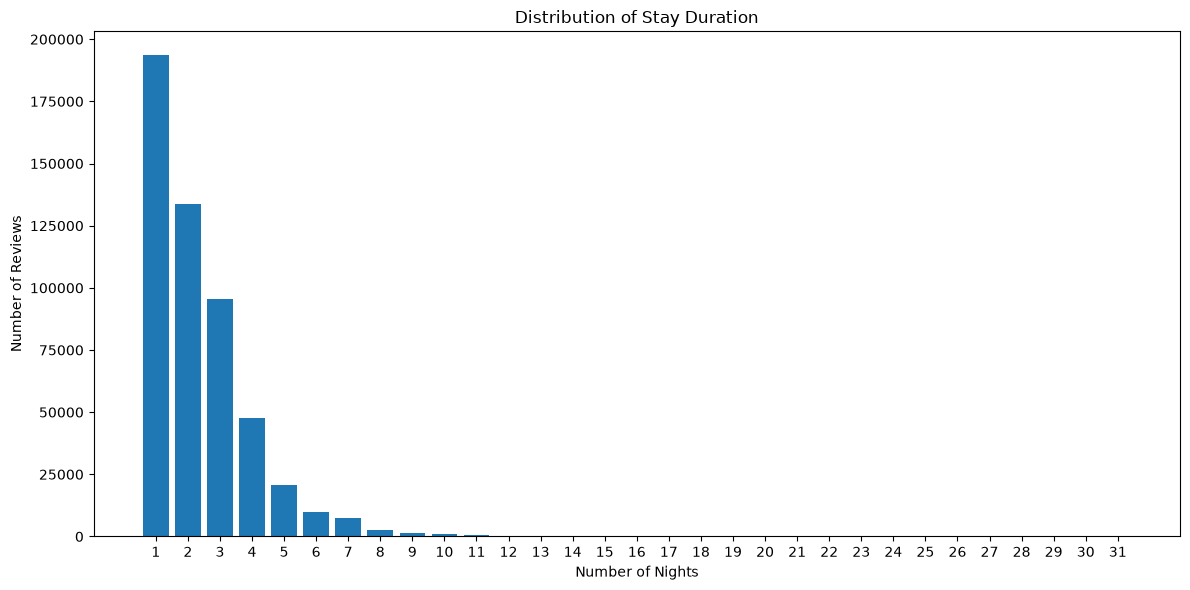

In [23]:
plt.figure(figsize=(12, 6))

plt.bar(
    stay_duration["Stay_Nights"],
    stay_duration["Review_Count"]
)

plt.title("Distribution of Stay Duration")
plt.xlabel("Number of Nights")
plt.ylabel("Number of Reviews")
plt.xticks(range(1, 32))
plt.tight_layout()
plt.show()

In [24]:
stay_sentiment = (
    df.groupby(["Stay_Nights", "VADER_Sentiment"])
    .size()
    .unstack(fill_value=0)
)

stay_sentiment_percentage = (
    stay_sentiment
    .div(stay_sentiment.sum(axis=1), axis=0)
    .mul(100)
)

print("===== SENTIMENT BY STAY DURATION =====")
print(stay_sentiment_percentage.round(2))

===== SENTIMENT BY STAY DURATION =====
VADER_Sentiment  Negative  Neutral  Positive
Stay_Nights                                 
1.0                 22.17     7.10     70.73
2.0                 20.80     7.06     72.14
3.0                 20.01     6.78     73.21
4.0                 19.74     6.92     73.33
5.0                 20.45     7.69     71.86
6.0                 20.75     7.95     71.30
7.0                 20.93     8.33     70.75
8.0                 21.10     9.61     69.30
9.0                 21.89    10.21     67.90
10.0                23.45    10.48     66.07
11.0                25.66     9.83     64.51
12.0                22.15    11.08     66.77
13.0                23.98    11.38     64.63
14.0                31.58     9.31     59.11
15.0                25.64    11.97     62.39
16.0                31.58    12.28     56.14
17.0                14.29     7.14     78.57
18.0                30.30    15.15     54.55
19.0                24.14    13.79     62.07
20.0            

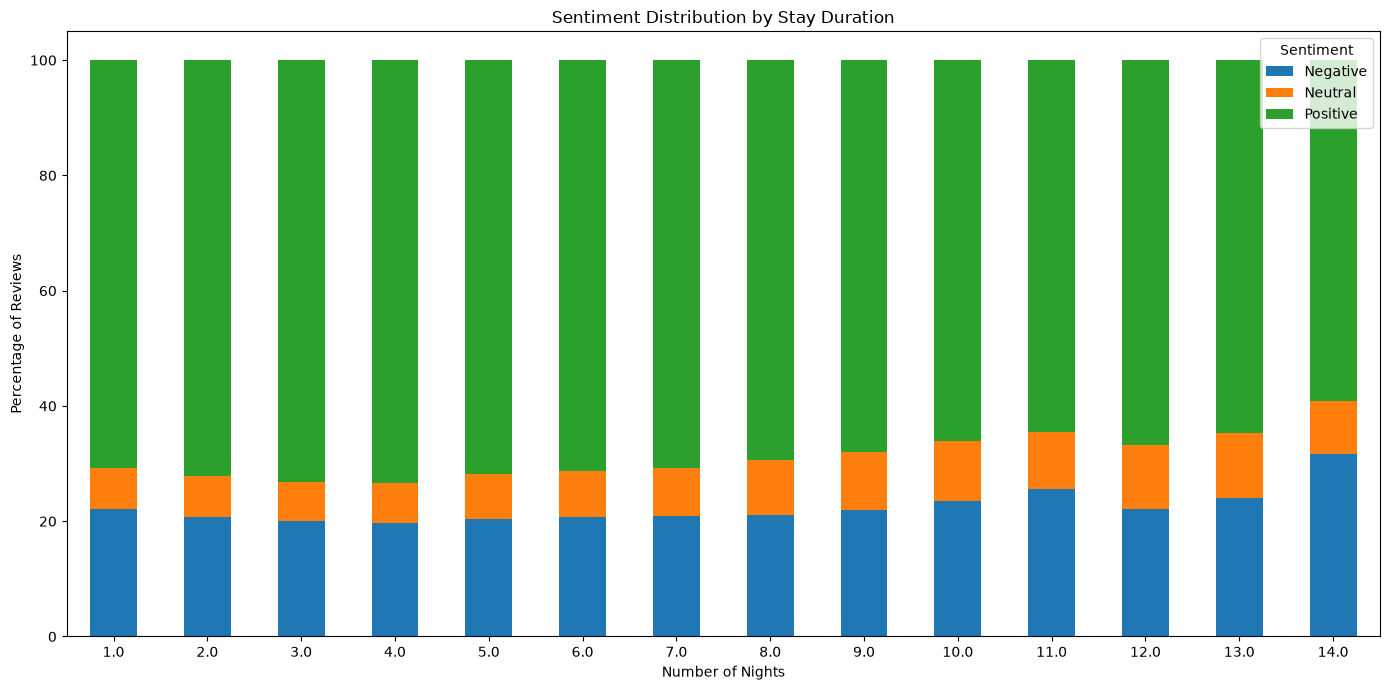

In [25]:
stay_sentiment_14 = stay_sentiment_percentage.loc[
    stay_sentiment_percentage.index <= 14
]

stay_sentiment_14.plot(
    kind="bar",
    stacked=True,
    figsize=(14, 7)
)

plt.title("Sentiment Distribution by Stay Duration")
plt.xlabel("Number of Nights")
plt.ylabel("Percentage of Reviews")
plt.legend(title="Sentiment")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [26]:
repeat_visit = df["Total_Number_of_Reviews_Reviewer_Has_Given"].value_counts().sort_index()

print("===== REVIEWER REVIEW HISTORY =====")
print(repeat_visit.head(20))

===== REVIEWER REVIEW HISTORY =====
Total_Number_of_Reviews_Reviewer_Has_Given
1     154506
2      67011
3      46802
4      34991
5      27604
6      22593
7      18599
8      16126
9      13526
10     11702
11      9980
12      8995
13      7755
14      6752
15      5927
16      5376
17      4860
18      4384
19      3802
20      3427
Name: count, dtype: int64


In [27]:
df["Reviewer_Type"] = np.where(
    df["Total_Number_of_Reviews_Reviewer_Has_Given"] == 1,
    "First-Time Reviewer",
    "Repeat Reviewer"
)

reviewer_type_counts = (
    df["Reviewer_Type"]
    .value_counts()
    .reset_index()
)

reviewer_type_counts.columns = ["Reviewer_Type", "Review_Count"]

print("===== FIRST-TIME VS REPEAT REVIEWERS =====")
print(reviewer_type_counts)

print("\nPercentage:")
print(
    (reviewer_type_counts["Review_Count"] / len(df) * 100)
    .round(2)
)

===== FIRST-TIME VS REPEAT REVIEWERS =====
         Reviewer_Type  Review_Count
0      Repeat Reviewer        360706
1  First-Time Reviewer        154506

Percentage:
0    70.01
1    29.99
Name: Review_Count, dtype: float64


In [28]:
reviewer_sentiment = (
    df.groupby(["Reviewer_Type", "VADER_Sentiment"])
    .size()
    .unstack(fill_value=0)
)

reviewer_sentiment_percentage = (
    reviewer_sentiment
    .div(reviewer_sentiment.sum(axis=1), axis=0)
    .mul(100)
)

print("===== SENTIMENT BY REVIEWER TYPE =====")
print(reviewer_sentiment_percentage.round(2))

===== SENTIMENT BY REVIEWER TYPE =====
VADER_Sentiment      Negative  Neutral  Positive
Reviewer_Type                                   
First-Time Reviewer     21.40     7.19     71.40
Repeat Reviewer         20.95     7.07     71.97


In [29]:
nationality_reviews = (
    df["Reviewer_Nationality"]
    .value_counts()
    .reset_index()
)

nationality_reviews.columns = ["Nationality", "Review_Count"]

print("===== TOP 20 REVIEWER NATIONALITIES =====")
print(nationality_reviews.head(20))

===== TOP 20 REVIEWER NATIONALITIES =====
                 Nationality  Review_Count
0             United Kingdom        245110
1   United States of America         35349
2                  Australia         21648
3                    Ireland         14814
4       United Arab Emirates         10229
5               Saudi Arabia          8940
6                Netherlands          8757
7                Switzerland          8669
8                    Germany          7929
9                     Canada          7883
10                    France          7265
11                    Israel          6601
12                     Italy          6113
13                   Belgium          6024
14                    Turkey          5440
15                    Kuwait          4915
16                     Spain          4735
17                   Romania          4548
18                    Russia          3898
19              South Africa          3816


In [30]:
nationality_counts = (
    df["Reviewer_Nationality"]
    .value_counts()
)

valid_nationalities = nationality_counts[
    nationality_counts >= 1000
].index

nationality_sentiment = (
    df[df["Reviewer_Nationality"].isin(valid_nationalities)]
    .groupby(["Reviewer_Nationality", "VADER_Sentiment"])
    .size()
    .unstack(fill_value=0)
)

nationality_sentiment_percentage = (
    nationality_sentiment
    .div(nationality_sentiment.sum(axis=1), axis=0)
    .mul(100)
    .sort_values("Positive", ascending=False)
)

print("===== NATIONALITY SENTIMENT (MIN. 1000 REVIEWS) =====")
print(nationality_sentiment_percentage.round(2))

===== NATIONALITY SENTIMENT (MIN. 1000 REVIEWS) =====
VADER_Sentiment           Negative  Neutral  Positive
Reviewer_Nationality                                 
New Zealand                  18.28     5.20     76.52
Finland                      18.87     4.81     76.31
United States of America     18.51     5.36     76.14
Australia                    18.52     5.49     75.99
Ireland                      18.78     5.70     75.52
Canada                       19.18     5.66     75.16
United Kingdom               19.75     6.38     73.86
Israel                       19.98     6.29     73.73
Hungary                      20.88     5.40     73.72
Germany                      21.69     5.54     72.77
Denmark                      22.25     5.06     72.69
Netherlands                  20.98     6.69     72.33
Malta                        18.79     8.92     72.29
Norway                       21.66     6.34     72.00
Switzerland                  22.11     6.11     71.77
Sweden                      

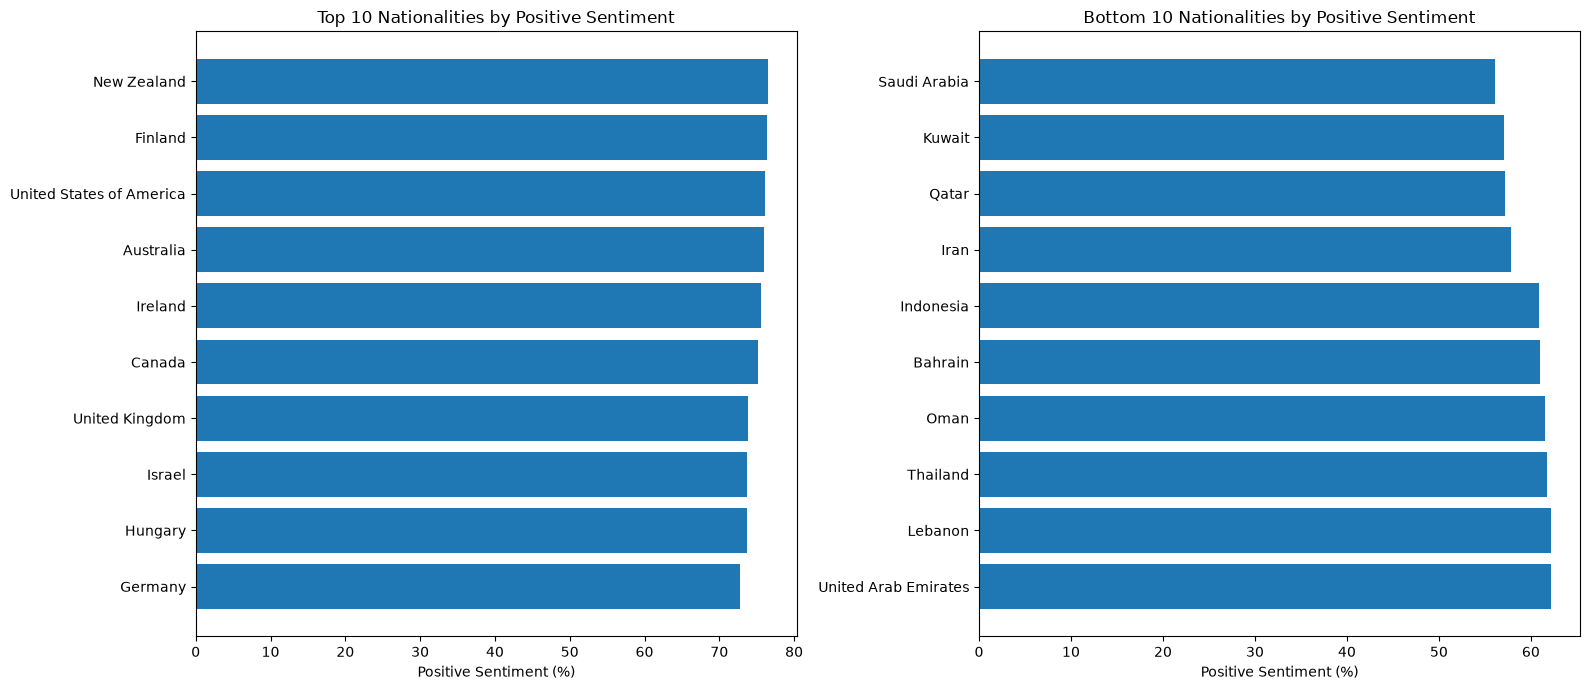

In [31]:
top_positive_nationalities = (
    nationality_sentiment_percentage
    .sort_values("Positive", ascending=False)
    .head(10)
)

bottom_positive_nationalities = (
    nationality_sentiment_percentage
    .sort_values("Positive", ascending=True)
    .head(10)
)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

axes[0].barh(
    top_positive_nationalities.index[::-1],
    top_positive_nationalities["Positive"][::-1]
)

axes[0].set_title("Top 10 Nationalities by Positive Sentiment")
axes[0].set_xlabel("Positive Sentiment (%)")

axes[1].barh(
    bottom_positive_nationalities.index[::-1],
    bottom_positive_nationalities["Positive"][::-1]
)

axes[1].set_title("Bottom 10 Nationalities by Positive Sentiment")
axes[1].set_xlabel("Positive Sentiment (%)")

plt.tight_layout()
plt.show()

In [32]:
stay_summary = (
    df["Stay_Nights"]
    .value_counts()
    .sort_index()
    .reset_index()
)

stay_summary.columns = ["Stay_Nights", "Review_Count"]

stay_summary["Percentage"] = (
    stay_summary["Review_Count"]
    / stay_summary["Review_Count"].sum()
    * 100
)

print("===== TOP 10 STAY DURATIONS =====")
print(
    stay_summary
    .sort_values("Review_Count", ascending=False)
    .head(10)
    .round(2)
)

===== TOP 10 STAY DURATIONS =====
   Stay_Nights  Review_Count  Percentage
0          1.0        193497       37.57
1          2.0        133809       25.98
2          3.0         95706       18.58
3          4.0         47750        9.27
4          5.0         20818        4.04
5          6.0          9754        1.89
6          7.0          7387        1.43
7          8.0          2498        0.49
8          9.0          1293        0.25
9         10.0           887        0.17


In [33]:
print("===== MAJOR TRAVEL TRENDS =====")

print("\n1. Most reviewed city:")
print(city_reviews.iloc[0]["City"], "-", city_reviews.iloc[0]["Review_Count"], "reviews")

print("\n2. Most common stay duration:")
print(
    stay_summary.sort_values("Review_Count", ascending=False).iloc[0]["Stay_Nights"],
    "night -",
    round(
        stay_summary.sort_values("Review_Count", ascending=False).iloc[0]["Percentage"],
        2
    ),
    "%"
)

print("\n3. Average stay duration:")
print(round(df["Stay_Nights"].mean(), 2), "nights")

print("\n4. Most common reviewer type:")
print(
    reviewer_type_counts.iloc[0]["Reviewer_Type"],
    "-",
    reviewer_type_counts.iloc[0]["Review_Count"],
    "reviews"
)

print("\n5. Most positive nationality:")
print(
    nationality_sentiment_percentage["Positive"].idxmax(),
    "-",
    round(nationality_sentiment_percentage["Positive"].max(), 2),
    "%"
)

print("\n6. Most negative nationality:")
print(
    nationality_sentiment_percentage["Negative"].idxmax(),
    "-",
    round(nationality_sentiment_percentage["Negative"].max(), 2),
    "%"
)

===== MAJOR TRAVEL TRENDS =====

1. Most reviewed city:
London - 262298 reviews

2. Most common stay duration:
1.0 night - 37.57 %

3. Average stay duration:
2.36 nights

4. Most common reviewer type:
Repeat Reviewer - 360706 reviews

5. Most positive nationality:
New Zealand - 76.52 %

6. Most negative nationality:
Iran - 29.27 %


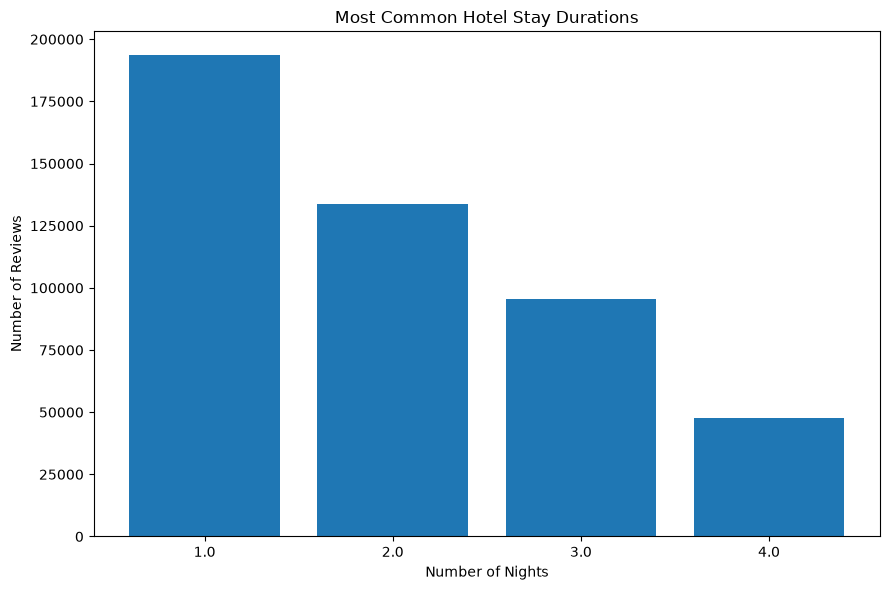

In [34]:
top_stay_durations = (
    stay_summary
    .sort_values("Review_Count", ascending=False)
    .head(4)
    .sort_values("Stay_Nights")
)

plt.figure(figsize=(9, 6))

plt.bar(
    top_stay_durations["Stay_Nights"].astype(str),
    top_stay_durations["Review_Count"]
)

plt.title("Most Common Hotel Stay Durations")
plt.xlabel("Number of Nights")
plt.ylabel("Number of Reviews")

plt.tight_layout()
plt.show()

In [35]:
print("===== FINAL TREND ANALYSIS VERIFICATION =====")

print("\nDataset Shape:")
print(df.shape)

print("\nAnalysis Columns:")
analysis_columns = [
    "Review_Date",
    "Review_Month",
    "Review_Year",
    "City",
    "Stay_Nights",
    "Reviewer_Type",
    "VADER_Sentiment"
]

for column in analysis_columns:
    print(f"{column}: {'✓' if column in df.columns else '✗'}")

print("\nMissing Values in Key Analysis Columns:")
print(df[analysis_columns].isna().sum())

print("\nDate Range:")
print(df["Review_Date"].min(), "to", df["Review_Date"].max())

print("\nTotal Reviews:")
print(len(df))

print("\n===== VERIFICATION COMPLETE =====")

===== FINAL TREND ANALYSIS VERIFICATION =====

Dataset Shape:
(515212, 26)

Analysis Columns:
Review_Date: ✓
Review_Month: ✓
Review_Year: ✓
City: ✓
Stay_Nights: ✓
Reviewer_Type: ✓
VADER_Sentiment: ✓

Missing Values in Key Analysis Columns:
Review_Date          0
Review_Month         0
Review_Year          0
City                 0
Stay_Nights        192
Reviewer_Type        0
VADER_Sentiment      0
dtype: int64

Date Range:
2015-08-04 00:00:00 to 2017-08-03 00:00:00

Total Reviews:
515212

===== VERIFICATION COMPLETE =====


In [36]:
print("Current dataframe shape:", df.shape)
print("\nCurrent columns:")
print(df.columns.tolist())

Current dataframe shape: (515212, 26)

Current columns:
['Hotel_Address', 'Additional_Number_of_Scoring', 'Review_Date', 'Average_Score', 'Hotel_Name', 'Reviewer_Nationality', 'Negative_Review', 'Review_Total_Negative_Word_Counts', 'Total_Number_of_Reviews', 'Positive_Review', 'Review_Total_Positive_Word_Counts', 'Total_Number_of_Reviews_Reviewer_Has_Given', 'Reviewer_Score', 'Tags', 'days_since_review', 'lat', 'lng', 'Rating_Sentiment', 'Review_Text', 'VADER_Compound', 'VADER_Sentiment', 'Review_Month', 'Review_Year', 'City', 'Stay_Nights', 'Reviewer_Type']


In [37]:
powerbi_file = "../data/cleaned/Hotel_Reviews_PowerBI.csv"

df.to_csv(
    powerbi_file,
    index=False
)

print("Power BI dataset saved successfully!")
print("File:", powerbi_file)
print("Shape:", df.shape)

Power BI dataset saved successfully!
File: ../data/cleaned/Hotel_Reviews_PowerBI.csv
Shape: (515212, 26)
